# Análisis de Datos II
### Pablo Salvagni

## Consigna

### Actividad 3. Reducción de dimensionalidad y clustering

Crear un pipeline de ML no supervisado para explorar la estructura de un dataset, identificar patrones y grupos, y extraer conocimiento útil de los datos.

**Dataset elegido:** Human Activity Recognition Using Smartphones

---

### 2. Análisis exploratorio y preprocesamiento (obligatorio, 1 punto)

- Descripción del dataset. ¿Qué representa cada observación?
- Análisis y visualización de tipos de datos (numéricos, categóricos, imágenes, etc.).
- Obtención de una representación adecuada, si corresponde (por ej. embeddings en el caso de texto).
- Tratamiento de valores faltantes y normalización/estandarización si la técnica a aplicar lo requiere.

### 3. Reducción de dimensionalidad y clustering (obligatorio, 7 puntos)

**a)** Aplicar reducción de dimensionalidad para obtener una representación compacta de los datos, conservando la mayor cantidad de información posible.

**b)** Entrenar al menos dos algoritmos de clustering diferentes sobre la representación obtenida mediante reducción de dimensionalidad.

> **Importante:** la variable target no debe utilizarse para realizar la reducción de dimensionalidad ni para construir los clusters. Solo se debe usar para el análisis e interpretación posterior de los grupos.

**c)** Evaluar y comparar los resultados de los distintos algoritmos de clustering. Analizar las diferencias entre las soluciones obtenidas y determinar cuál resulta más adecuada para los datos, utilizando métricas de evaluación y/o visualizaciones de los clusters. Justificar la selección de una de las soluciones para el análisis posterior.

**d)** Interpretar los clusters resultantes del algoritmo de clustering seleccionado. ¿Qué estructura de los datos está capturando el clustering? ¿Qué información aportan los grupos encontrados?

- **En problemas de clasificación:** analizar la composición de cada cluster según las categorías conocidas. Por ejemplo, determinar qué clases predominan en cada cluster, qué clases tienden a agruparse y cuáles presentan mayor solapamiento. ¿Existe una correspondencia entre los clusters encontrados y las categorías reales? ¿Los grupos identificados presentan una interpretación coherente con el dominio?
- **En problemas de regresión:** analizar cómo se distribuye la variable target entre los clusters. Por ejemplo, comparar sus medias, medianas, dispersión o distribución. No se espera necesariamente que los clusters expliquen la variable target; el objetivo es determinar si existen diferencias en target que permitan caracterizar o interpretar los grupos.

**En todos los casos:**

- Complementar el análisis con observaciones representativas de cada cluster.
- Describir qué características distinguen a los diferentes grupos.
- Explicar qué información aportan los clusters sobre los datos y el problema analizado.

### 4. Visualización e interpretación con UMAP (opcional, 2 puntos)

A partir de los datos originales, aplicar UMAP para obtener una representación bidimensional de los datos y visualizar su estructura. Analizar e interpretar los patrones observados, por ejemplo, regiones diferenciadas, separaciones, zonas de mayor o menor densidad, posibles agrupamientos o puntos aislados. ¿Qué información aporta esta representación y qué conclusiones pueden extraerse a partir de ella?

---

### Forma de entrega

Enlace a una notebook en un repositorio de acceso público. Lo importante es que el código esté ejecutado (que muestre la salida).

La notebook debe contener el storytelling: hipótesis, el proceso de selección de técnicas, las visualizaciones y las conclusiones de dominio obtenidas.

### Evaluación

- Se evaluará que se haya respetado la consigna y que haya una interpretación adecuada de los resultados.
- No se evaluará haber realizado un EDA o preprocesamiento exhaustivos. El foco está en el análisis e interpretación de los resultados.

In [45]:
# librearias necsarias para el tp
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    adjusted_rand_score,
    adjusted_mutual_info_score,
)

import umap


#### 1. Importación de dataset

El dataset elegido es: [Human Activity Recognition (HAR)](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones)

Es un problema de **clasificación**. Los datos se tomaron de 30 personas, entre 19 y 48 años, que realizaron 6 actividades con un smartphone (Samsung Galaxy S II) en la cintura. A partir del acelerometro y el giroscopio se extrajeron **561 features** por ventana de tiempo, repartidas en train (7352) y test (2947): **10299 filas** en total.

Las 6 actividades ([target](dataset/activity_labels.txt)) son:

| id | actividad | tipo |
|----|-----------|------|
| 1 | WALKING | dinámica |
| 2 | WALKING_UPSTAIRS | dinámica |
| 3 | WALKING_DOWNSTAIRS | dinámica |
| 4 | SITTING | estática |
| 5 | STANDING | estática |
| 6 | LAYING | estática |

**Objetivo del TP:** como es un pipeline no supervisado, no uso `activity` para reducir dimensionalidad ni para armar los clusters. La idea es ver qué estructura encuentra el clustering por sí solo y recién después compararla contra estas 6 clases para interpretar los grupos.


In [ ]:

def load_har(base="dataset"):

    # leemos los 561 nombes de las columnas de featres.txt
    feat = pd.read_csv(
        f"{base}/features.txt", sep=r"\s+", header=None, names=["idx", "name"]
    )
    
    # HAR tiene nombres de features repetidos
    names = pd.Series(feat["name"]).astype(str)
    names = names + "_" + names.groupby(names).cumcount().astype(str)
    names = names.str.replace("_0$", "", regex=True)

    # Leemos las variables target de activity_labels.txt
    labels = pd.read_csv(
        f"{base}/activity_labels.txt",
        sep=r"\s+",
        header=None,
        names=["activity_id", "activity"],
    )

    # el dataset viene partido entre train y test. Leo ambos y los uno
    def _split(split):
        X = pd.read_csv(
            f"{base}/{split}/X_{split}.txt", sep=r"\s+", header=None, names=names
        )
        y = pd.read_csv(
            f"{base}/{split}/y_{split}.txt", sep=r"\s+", header=None, names=["activity_id"]
        )
        subj = pd.read_csv(
            f"{base}/{split}/subject_{split}.txt",
            sep=r"\s+",
            header=None,
            names=["subject"],
        )
        return pd.concat([X, y, subj], axis=1)

    # uno train y test en un solo df, al ser no supervisado no hace falta el split
    df = pd.concat([_split("train"), _split("test")], ignore_index=True)
    df = df.merge(labels, on="activity_id", how="left")
    return df


df = load_har()
df.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",activity_id,subject,activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,5,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,5,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,5,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,5,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,5,1,STANDING


Cada fila es una ventana de **2.56s** de una persona haciendo una actividad cotidiana, con el celular en la cintura. Hay **561** features numericas extraidas del acelerometro y el giroscopio (ya vienen normalizadas en [-1, 1]) y 6 actividades.

Unimos train y test porque el problema seria **no** supervisado: no hace falta el split. El target es `activity` y no se usa para PCA ni para armar los clusters. `subject` es el id de la persona, tampoco entra como feature.

#### 2. Realizamos un mini EDA

In [ ]:
# mini EDA con filas, columnas, tipos de datos, faltantes, nulos, etc 
print(df.shape)
print(df.dtypes.value_counts())
print("faltantes:", df.isna().sum().sum())
print("personas (subject):", df["subject"].nunique())
print(df["activity"].value_counts())

feature_cols = [c for c in df.columns if c not in ["activity", "activity_id", "subject"]]
print("features numericas:", len(feature_cols))
print("rango features: min", df[feature_cols].min().min(), "max", df[feature_cols].max().max())

(10299, 564)
float64    561
int64        2
str          1
Name: count, dtype: int64
faltantes: 0
personas (subject): 30
activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64
features numericas: 561
rango features: min -1.0 max 1.0


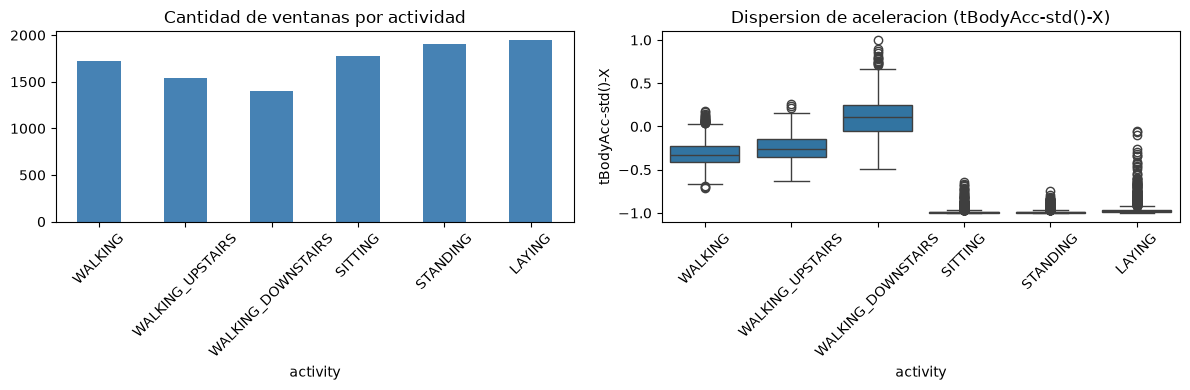

In [ ]:
# definimos orden de las activides para aplicar en todos los graficos.
orden = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING",
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# grafico izquierdo: cantidad de ventanas por actividad
df["activity"].value_counts().reindex(orden).plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Cantidad de ventanas por actividad")
axes[0].tick_params(axis="x", rotation=45)

# grafico derecho: dispersion de aceleracion
sns.boxplot(
    data=df,
    x="activity",
    y="tBodyAcc-std()-X",
    order=orden,
    ax=axes[1],
)

axes[1].set_title("Dispersion de aceleracion (tBodyAcc-std()-X)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Conclusion del mini EDA

- **10299** filas (train + test) y **561** features numericas. No hay texto ni imagenes: ya vienen extraidas de las senales.
- **0** faltantes. No hay que imputar.
- Las 6 actividades estan bastante **balanceadas**.
- Features ya normalizadas en **[-1, 1]**. Igual voy a estandarizar para PCA y K-means (como vimos en clase).
- `subject` son 30 personas. No entra como feature.
- En `tBodyAcc-std()-X` se ve la diferencia que esperaba: caminar / subir / bajar tienen mucha mas dispersion que sentado / parado / acostado.

**Hipotesis**

1. Las actividades **dinamicas** (WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS) se van a parecer entre si.
2. **SITTING** y **STANDING** se van a solapar: el celu esta en la cintura y hay poca aceleracion.
3. **LAYING** deberia separarse mas del resto.

El clustering no tiene por que copiar las 6 etiquetas. Si arma grupos de movimiento vs reposo, igual es coherente con el dominio.

#### 3. Preprocesamiento

In [ ]:
# separo el target (activity) ANTES de modelar: NO entra a PCA ni al clustering
target = df["activity"].copy()
X = df.drop(columns=["activity", "activity_id", "subject"])

# PCA se basa en varianza entonces escalo para que todas las features pesen igual
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X.shape)
print(X_scaled.mean(), X_scaled.std())

(10299, 561)
1.8009099792273252e-17 1.0


Saco `activity` y `subject` de X. El target queda guardado para interpretar los clusters despues, no para entrenar.

Las features ya venian en [-1, 1], pero `StandardScaler` deja media 0 y varianza 1. PCA y K-means son sensibles a la escala, por eso lo aplico igual.

#### 3.a Reducción de dimensionalidad (PCA)

561 features es mucha dimensión para clusterizar (maldición de la dimensionalidad). Uso PCA para compactar, como en clase: me quedo con las componentes que juntan el **90%** de la varianza. El target no entra.

componentes: 65
varianza acumulada: 0.900483334682293


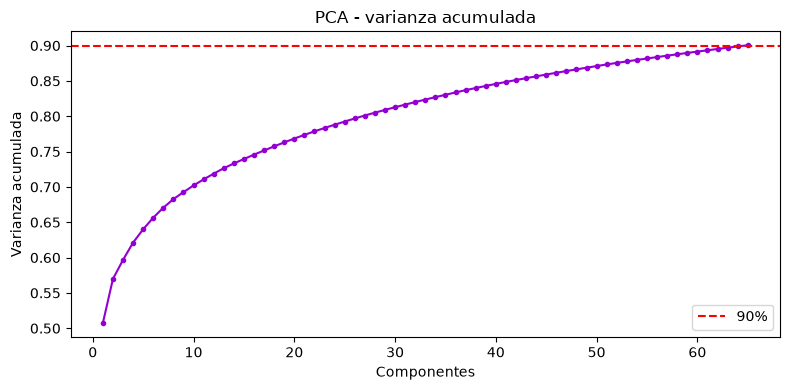

In [ ]:
# n_components=0.90 > sklearn elige automaticamente cuantas componentes hacen falta
# para retener el 90% de la varianza (en vez de fijar yo el numero a mano)

pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X_scaled)

var_acum = np.cumsum(pca.explained_variance_ratio_)
print("componentes:", X_pca.shape[1])
print("varianza acumulada:", var_acum[-1])

# graficamos varianza de codo, intentando ver cuanta varianza junta a medida que suma componentes
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(var_acum) + 1), var_acum, "o-", markersize=3, color="darkviolet")
plt.axhline(0.90, color="red", ls="--", label="90%")
plt.xlabel("Componentes")
plt.ylabel("Varianza acumulada")
plt.title("PCA - varianza acumulada")
plt.legend()
plt.tight_layout()
plt.show()

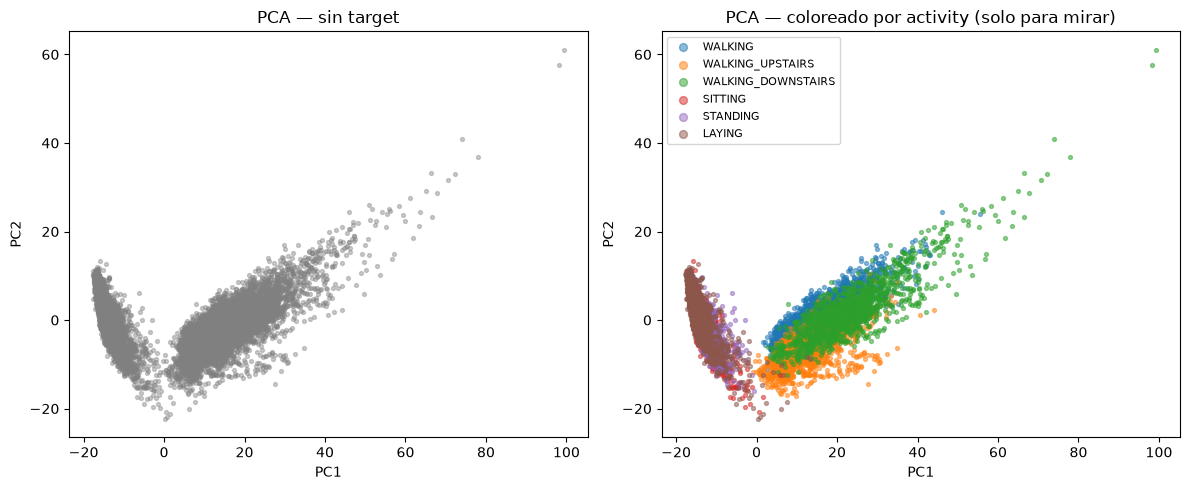

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# grafico izquierdo: PC1 vs PC2 sin color para veri ha a ojo hay dos nubes separadas.
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], s=8, alpha=0.4, c="gray")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].set_title("PCA — sin target")

for act in orden:
    mask = target == act
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], s=8, alpha=0.5, label=act)

# grafico derecho: PC1 vs PC2 coloreado por activity (solo para mirar), no se usa para calcular PCA
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("PCA — coloreado por activity (solo para mirar)")
axes[1].legend(markerscale=2, fontsize=8)

plt.tight_layout()
plt.show()

### Conclusion de PCA

- Paso de **561** features a **65 componentes**, que juntan el **90%** de la varianza (sale impreso en la celda de arriba). Es una reduccion grande manteniendo casi toda la informacion.
- El clustering va sobre `X_pca`, no sobre las 561 crudas.
- El plot de la derecha **no** se usó para entrenar: solo miro si PC1/PC2 ya separan movimiento vs reposo. Si se ve algo parecido a las hipótesis, bien; el clustering se hace en todas las componentes retenidas, no solo en 2.

#### 3.b Clustering

Entreno **K-means** y **GMM** sobre `X_pca`. Eligo `K` con silhouette (`K = 2..10`), como en clase. No fuerzo `K = 6` solo porque hay 6 actividades: el clustering no tiene que copiar las etiquetas.

K=2 | K-means=0.436 | GMM=0.405
K=3 | K-means=0.354 | GMM=0.245
K=4 | K-means=0.180 | GMM=0.202
K=5 | K-means=0.156 | GMM=0.162
K=6 | K-means=0.140 | GMM=0.135
K=7 | K-means=0.120 | GMM=0.103
K=8 | K-means=0.100 | GMM=0.078
K=9 | K-means=0.105 | GMM=0.100
K=10 | K-means=0.109 | GMM=0.101


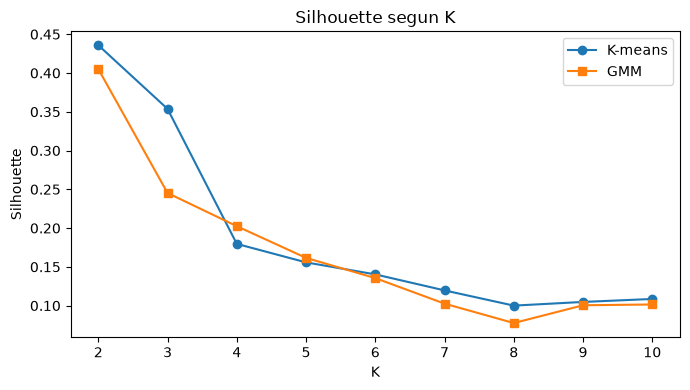

mejor K-means: 2 mejor GMM: 2


In [ ]:
# pruebo K de 2 a 10 y me quedo con el mejor silhouette
ks = range(2, 11)
sil_km = []
sil_gmm = []

for k in ks:
    # fit
    km_lab = KMeans(
        n_clusters=k, init="k-means++", n_init=10, random_state=42
    ).fit_predict(X_pca)
    gmm_lab = GaussianMixture(n_components=k, random_state=42).fit_predict(X_pca)
    sil_km.append(silhouette_score(X_pca, km_lab))
    sil_gmm.append(silhouette_score(X_pca, gmm_lab))
    print(f"K={k} | K-means={sil_km[-1]:.3f} | GMM={sil_gmm[-1]:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(list(ks), sil_km, "o-", label="K-means")
plt.plot(list(ks), sil_gmm, "s-", label="GMM")
plt.xlabel("K")
plt.ylabel("Silhouette")
plt.title("Silhouette segun K")
plt.legend()
plt.tight_layout()
plt.show()

# argmax de silhouette buscando el mejor K de cada metodo.
K_km = list(ks)[int(np.argmax(sil_km))]
K_gmm = list(ks)[int(np.argmax(sil_gmm))]
print("mejor K-means:", K_km, "mejor GMM:", K_gmm)

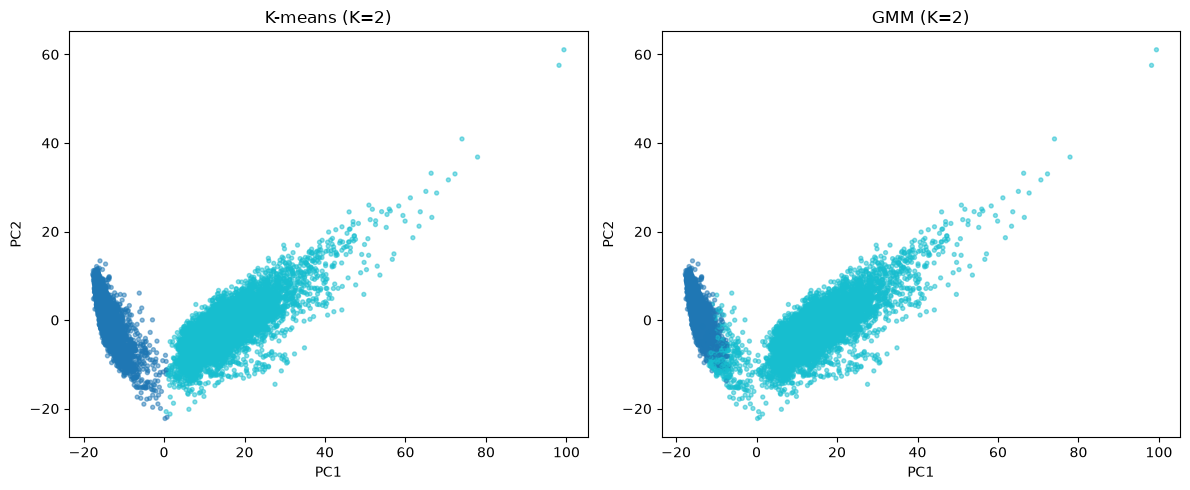

In [ ]:
# re entreno con el mejor K de cada metodo
km_labels = KMeans(
    n_clusters=K_km, init="k-means++", n_init=10, random_state=42
).fit_predict(X_pca)
gmm_labels = GaussianMixture(n_components=K_gmm, random_state=42).fit_predict(X_pca)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# grafico izquierdo: comparo K-means y GMM sobre PC1-PC2, coloreado por cluster
for ax, labels, title in [
    (axes[0], km_labels, f"K-means (K={K_km})"),
    (axes[1], gmm_labels, f"GMM (K={K_gmm})"),
]:
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, s=8, alpha=0.5, cmap="tab10")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title(title)

plt.tight_layout()
plt.show()

#### 3.c Evaluar y comparar

Comparo las dos soluciones con silhouette y con ARI/AMI entre ellas (consenso, no vs el target). El target lo uso recien en la interpretacion.

In [ ]:
# metricas internas (no usan target)
print("silhouette K-means:", silhouette_score(X_pca, km_labels))
print("silhouette GMM:", silhouette_score(X_pca, gmm_labels))
# metricas de consenso (usan target)
print("ARI K-means vs GMM:", adjusted_rand_score(km_labels, gmm_labels))
print("AMI K-means vs GMM:", adjusted_mutual_info_score(km_labels, gmm_labels))

silhouette K-means: 0.4358313424871076
silhouette GMM: 0.40512381651909635
ARI K-means vs GMM: 0.8520978753340925
AMI K-means vs GMM: 0.8016933653170868


### Conclusion de la comparacion

Hay que separar dos numeros:

- **K** = cuantos clusters arma el modelo (2, 3, 4, ...). Aca el silhouette maximo fue en **K = 2** para los dos.
- **Silhouette** = que tan separados/compactos quedaron esos clusters (de -1 a 1; mas alto, mejor). K-means **0.44**, GMM **0.41**.
- **ARI** = que tanto coinciden las dos particiones entre si (0 = no se ponen de acuerdo, 1 = iguales). Aca **0.85**: casi el mismo recorte.

Me quedo con **K-means, K = 2** porque tiene mejor silhouette (0.44 vs 0.41) y en PC1-PC2 se ve la misma estructura. GMM dice casi lo mismo (ARI 0.85), no cambia la lectura.

K = 2 encaja con la hipotesis de movimiento vs reposo. No fuerzo K = 6.

No elijo segun ARI vs `activity`: eso va en la interpretacion.

#### 3.d Interpretar los clusters

Uso K-means con K = 2. Ahora si miro el target: composicion de cada cluster vs las 6 actividades. Esto es el crosstab (la "matriz de confusion" del clustering: cluster no es una clase, por eso no hay diagonal de 6x6).

activity  WALKING  WALKING_UPSTAIRS  WALKING_DOWNSTAIRS  SITTING  STANDING  \
cluster                                                                      
0               0                 8                   0     1774      1906   
1            1722              1536                1406        3         0   

activity  LAYING  
cluster           
0           1932  
1             12  

% de cada actividad que cayo en cada cluster:
activity  WALKING  WALKING_UPSTAIRS  WALKING_DOWNSTAIRS  SITTING  STANDING  \
cluster                                                                      
0             0.0               0.5                 0.0     99.8     100.0   
1           100.0              99.5               100.0      0.2       0.0   

activity  LAYING  
cluster           
0           99.4  
1            0.6  

ARI cluster vs activity: 0.3296106738894193
AMI cluster vs activity: 0.5453746314089359


/var/folders/d9/jdkvkdkj05vcnpwfbz5dxz7m0000gn/T/ipykernel_47636/819724168.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["cluster"] = km_labels


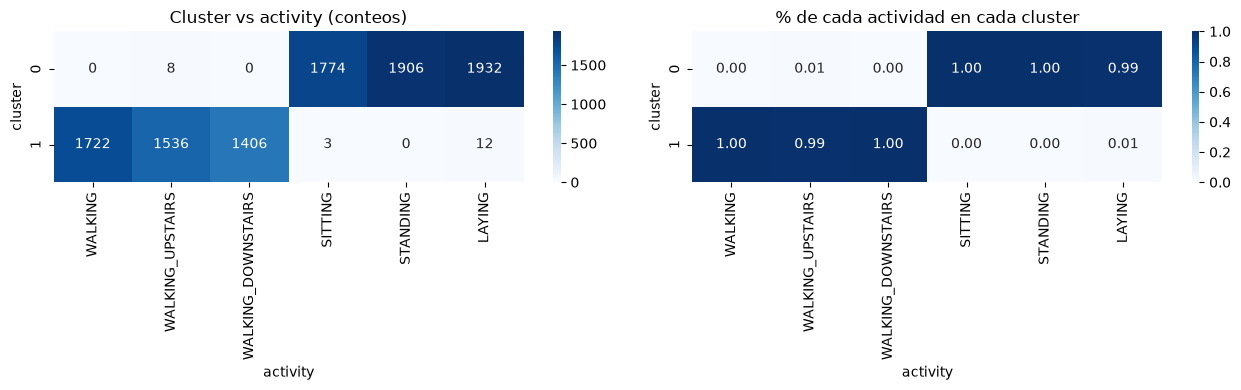

In [ ]:
# ACA recien usamos el target: pego el cluster al df para interpretar quien cayo donde
df["cluster"] = km_labels

ct = pd.crosstab(df["cluster"], df["activity"]).reindex(columns=orden)
ct_pct = pd.crosstab(df["cluster"], df["activity"], normalize="columns").reindex(columns=orden)

print(ct)
print("\n% de cada actividad que cayo en cada cluster:")
print((ct_pct * 100).round(1))

# ARI/AMI aca comparan CLUSTER vs TARGET real
print("\nARI cluster vs activity:", adjusted_rand_score(df["cluster"], df["activity"]))
print("AMI cluster vs activity:", adjusted_mutual_info_score(df["cluster"], df["activity"]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Cluster vs activity (conteos)")
sns.heatmap(ct_pct, annot=True, fmt=".2f", cmap="Blues", ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("% de cada actividad en cada cluster")
plt.tight_layout()
plt.show()

In [ ]:
# resumen de la feature 
print(df.groupby("cluster")["tBodyAcc-std()-X"].agg(["mean", "median", "count"]))

# una fila de ejemplo por cluster
print("\n--- observaciones representativas ---")
for c in sorted(df["cluster"].unique()):
    print(f"\ncluster {c}")
    print(
        df.loc[df["cluster"] == c, ["activity", "tBodyAcc-std()-X", "subject"]]
        .groupby("activity")
        .head(1)
    )

             mean    median  count
cluster                           
0       -0.976636 -0.991176   5620
1       -0.164751 -0.223519   4679

--- observaciones representativas ---

cluster 0
              activity  tBodyAcc-std()-X  subject
0             STANDING         -0.995279        1
27             SITTING         -0.904300        1
51              LAYING         -0.914811        1
5245  WALKING_UPSTAIRS         -0.455975       25

cluster 1
               activity  tBodyAcc-std()-X  subject
66               LAYING         -0.633135        1
78              WALKING         -0.328280        1
125  WALKING_DOWNSTAIRS         -0.171988        1
150    WALKING_UPSTAIRS         -0.367516        1
564             SITTING         -0.738075        3


### Analisis de los grupos

##### ¿Qué clases predominan?

- **Cluster 0 (reposo):** SITTING, STANDING y LAYING. Casi el 100% de esas tres actividades caen aca. Aceleracion baja (`tBodyAcc-std()-X` mediana ~ -0.99).
- **Cluster 1 (movimiento):** WALKING, WALKING_UPSTAIRS y WALKING_DOWNSTAIRS. El 99-100% de esas tres caen aca. Aceleracion mas alta.

##### ¿Cuáles se agrupan / se solapan?

Se agrupan las **dinamicas** entre si y las **estaticas** entre si. SITTING y STANDING se mezclan en el mismo cluster, como decia la hipotesis 2. LAYING **no** se separo del reposo: tambien quedo en el cluster 0. Hay poquisimas filtraciones (8 upstairs en 0, 12 laying en 1).

##### ¿Hay correspondencia con las 6 actividades?

No hay 6 clusters. El ARI vs `activity` da **0.33** porque estamos comparando 2 grupos contra 6 etiquetas: no puede dar alto. El AMI **0.55** igual muestra que comparten informacion: el corte que encontro es movimiento vs reposo, no las 6 clases.

##### ¿Es coherente con el dominio?

Si. El celu en la cintura distingue bien si la persona se esta moviendo o no. No distingue bien sentado vs parado vs acostado (poca aceleracion en los tres) ni caminar vs subir vs bajar (los tres son marcha). Eso es util: un sistema de activity recognition puede fallar entre esas clases parecidas, no porque el clustering este mal.

**Hipotesis:** 1 y 2 se cumplen. La 3 (LAYING mas aislado) **no**: LAYING se comporta como el resto del reposo.

#### 4. Visualización e interpretación con UMAP

UMAP va sobre los datos **originales ya escalados** (`X_scaled`), no sobre PCA. Es solo para ver la estructura en 2D. `n_neighbors=15` mira un poco el panorama global; `min_dist=0.1` no aplasta tanto los puntos.

In [ ]:
# UMAP = proyeccion no lineal a 2D solo para visualizar 
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    n_jobs=1,
    random_state=42,
)
X_umap = umap_model.fit_transform(X_scaled)
print(X_umap.shape)

(10299, 2)


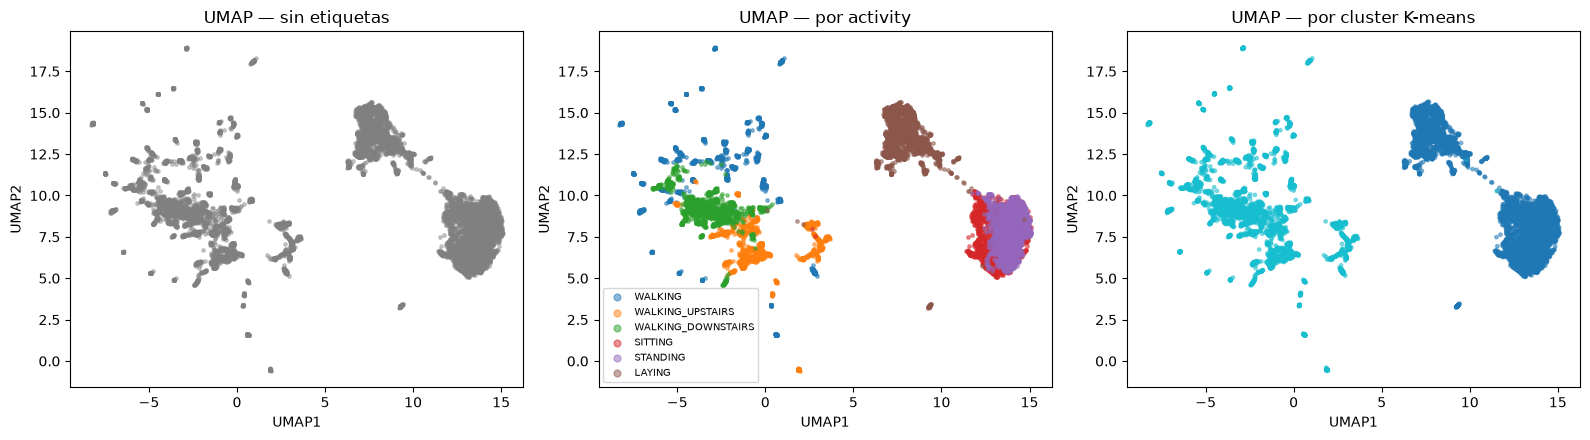

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Grafico de la izquierda, sin color: veo si hay estructura (2 nubes) o una sola mancha
axes[0].scatter(X_umap[:, 0], X_umap[:, 1], s=6, alpha=0.4, c="gray")
axes[0].set_title("UMAP — sin etiquetas")

# Grafico medio, coloreado por actividad real: para interpretar que hay en cada zona
for act in orden:
    mask = target == act
    axes[1].scatter(X_umap[mask, 0], X_umap[mask, 1], s=6, alpha=0.5, label=act)
axes[1].set_title("UMAP — por activity")
axes[1].legend(markerscale=2, fontsize=7)

# Grafico de la derecha, coloreado por cluster: si calza con (1) y (2), el K=2 no es un artefacto del PCA
axes[2].scatter(X_umap[:, 0], X_umap[:, 1], c=df["cluster"], s=6, alpha=0.5, cmap="tab10")
axes[2].set_title("UMAP — por cluster K-means")

for ax in axes:
    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")

plt.tight_layout()
plt.show()

### Conclusion de UMAP

UMAP parece no visualizar el target, se usa solo para visualizar en 2D. Mirando los 3 plots:

- **Sin etiquetas:** se ven claramente **2 regiones** separadas, unidas por un puente fino. No es una nube sola, hay estructura.
- **Por activity:** la region de la izquierda son las **3 caminatas** (WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS), que caen juntas pero bastante solapadas entre si. La region de la derecha son las **estaticas**: SITTING y STANDING quedan practicamente superpuestas (casi no se distinguen), y LAYING forma su propia sub-isla arriba, separada pero del mismo lado del reposo con un hilo que las une a las **estaticas**.
- **Por cluster:** los 2 clusters de K-means calzan casi exactos con esas 2 regiones. Eso confirma que **K=2 no es un artefacto de PCA**: la misma estructura aparece en una proyeccion totalmente distinta.

Sobre la hipotesis 3: LAYING **si** se despega como sub-isla, pero K=2 eligio el corte mas fuerte (movimiento vs reposo) y la dejo del lado de las estaticas. No es contradiccion, es que el clustering se quedo con la separacion dominante.

### Conclusion final

El dataset son ventanas de 2.56s de un celu en la cintura (561 features). El problema seria no supervisado: `activity` no entro a PCA ni al clustering.

PCA compacto de 561 a las componentes del 90% de varianza. Sobre eso compare K-means y GMM. Los dos eligen **K=2**, silhouette 0.44 vs 0.41, ARI entre ellos 0.85. Me quedo con **K-means**.

Esos 2 clusters no copian las 6 actividades. Cortan **movimiento vs reposo**: caminar/subir/bajar juntos, sentado/parado/acostado juntos. Tiene sentido para el dominio. LAYING no se aislo (la hipotesis 3 no se cumplio).

UMAP en 2D, sobre los datos originales, sirve para ver si esa misma estructura aparece sin usar PCA.